# DeepShieldAI: Enterprise Video Forensics Engine
## Module 09 — Temporal Sequence Modeling via Bidirectional GRU

![DeepShieldAI Banner](https://img.shields.io/badge/DeepShieldAI-Temporal%20Deep%20Learning-0284C7?style=for-the-badge&logo=shield&logoColor=white)
![Model](https://img.shields.io/badge/Architecture-Bidirectional%20GRU-10B981?style=for-the-badge)
![Optimization](https://img.shields.io/badge/Optimizer-Adam%20%7C%20BCE%20Loss-F59E0B?style=for-the-badge)

---

### Theoretical Formulation: Why Bidirectional GRU?
In video manipulation detection, single frame spatial classifiers are prone to false positives caused by natural motion blur or lighting shifts. 
DeepShieldAI employs a **Bidirectional Gated Recurrent Unit (Bi-GRU)** to model temporal dependencies:

1. **Gated Recurrent Mechanism**:
   $$z_t = \sigma(W_z x_t + U_z h_{t-1} + b_z) \quad \text{(Update Gate)}$$
   $$r_t = \sigma(W_r x_t + U_r h_{t-1} + b_r) \quad \text{(Reset Gate)}$$
   $$\tilde{h}_t = \tanh(W_h x_t + U_h (r_t \odot h_{t-1}) + b_h) \quad \text{(Candidate Activation)}$$
   $$h_t = (1 - z_t) \odot h_{t-1} + z_t \odot \tilde{h}_t \quad \text{(Final State)}$$
2. **Bidirectional Temporal Context**:
   - $\overrightarrow{h}_t$: Encodes chronological transitions from frame $0 \to 19$.
   - $\overleftarrow{h}_t$: Encodes retro-chronological transitions from frame $19 \to 0$.
   - Concatenated representation: $h_t = [\overrightarrow{h}_t \,;\, \overleftarrow{h}_t] \in \mathbb{R}^{128}$.
3. **Forensic Value**:
   Generative facial artifacts often exhibit temporal "glitches" that are unnatural when inspected both forwards and backwards in time.


In [1]:
import os
import sys
import json
import time
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

# Deterministic Seed
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"TensorFlow Version : {tf.__version__}")
print(f"Keras Version      : {tf.keras.__version__}")


TensorFlow Version : 2.21.0
Keras Version      : 3.15.1


In [2]:
@dataclass
class TrainingConfig:
    seed: int = 42
    timesteps: int = 20
    feature_dim: int = 1280
    gru_units: int = 64
    dense_units: int = 64
    dropout_rate: float = 0.3
    learning_rate: float = 0.001
    batch_size: int = 16
    epochs: int = 20
    
    base_dir: str = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.path.abspath(".")
    processed_dir: str = os.path.join(base_dir, "datasets", "video_deepfake", "processed")
    models_dir: str = os.path.join(base_dir, "models")
    plots_dir: str = os.path.join(base_dir, "outputs", "plots")
    reports_dir: str = os.path.join(base_dir, "outputs", "reports")

cfg = TrainingConfig()
print(f"Models Directory  : {cfg.models_dir}")
print(f"Reports Directory : {cfg.reports_dir}")


Models Directory  : C:\Users\Nandhupriya\DeepShieldAI\models
Reports Directory : C:\Users\Nandhupriya\DeepShieldAI\outputs\reports


### 1. Ingestion of Precomputed Feature Embeddings
We load `train_features.npy`, `train_labels.npy`, `val_features.npy`, and `val_labels.npy`.


In [3]:
X_train = np.load(os.path.join(cfg.processed_dir, "train_features.npy"))
y_train = np.load(os.path.join(cfg.processed_dir, "train_labels.npy"))
X_val   = np.load(os.path.join(cfg.processed_dir, "val_features.npy"))
y_val   = np.load(os.path.join(cfg.processed_dir, "val_labels.npy"))

print(f"Training Tensors   : X={X_train.shape}, y={y_train.shape} | Balance: {int((y_train == 0).sum())} Real, {int((y_train == 1).sum())} Fake")
print(f"Validation Tensors : X={X_val.shape}, y={y_val.shape}   | Balance: {int((y_val == 0).sum())} Real, {int((y_val == 1).sum())} Fake")


Training Tensors   : X=(79, 20, 1280), y=(79,) | Balance: 44 Real, 35 Fake
Validation Tensors : X=(13, 20, 1280), y=(13,)   | Balance: 7 Real, 6 Fake


### 2. DeepShieldAI Bi-GRU Sequence Architecture Construction
Architecture Specifications:
1. **Input Layer**: `(None, 20, 1280)`
2. **Bidirectional GRU**: 64 units each direction ($128$ concatenated temporal outputs), `return_sequences=False`
3. **Dropout Regularization**: $0.3$ rate
4. **Dense Representation Layer**: 64 units with ReLU activation and $L_2$ weight regularization ($10^{-4}$)
5. **Dropout Regularization**: $0.3$ rate
6. **Forensic Output Layer**: 1 unit with Sigmoid activation ($P(\text{FAKE})$)


In [4]:
def build_video_classifier(config: TrainingConfig) -> tf.keras.Model:
    """Constructs the Bidirectional GRU Video Forensics Classifier."""
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(config.timesteps, config.feature_dim), name="temporal_feature_input"),
        tf.keras.layers.Bidirectional(
            tf.keras.layers.GRU(config.gru_units, return_sequences=False),
            name="bidirectional_gru"
        ),
        tf.keras.layers.Dropout(config.dropout_rate, name="temporal_dropout_1"),
        tf.keras.layers.Dense(
            config.dense_units, 
            activation='relu', 
            kernel_regularizer=tf.keras.regularizers.l2(1e-4),
            name="dense_projection"
        ),
        tf.keras.layers.Dropout(config.dropout_rate, name="temporal_dropout_2"),
        tf.keras.layers.Dense(1, activation='sigmoid', name="forensic_verdict_prob")
    ], name="DeepShield_Video_Forensics_Classifier")
    
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=config.learning_rate),
        loss='binary_crossentropy',
        metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
    )
    return model

model = build_video_classifier(cfg)
model.summary()


Model: "DeepShield_Video_Forensics_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_gru               │ (None, 128)            │       516,864 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ temporal_dropout_1 (Dropout)    │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_projection (Dense)        │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ temporal_dropout_2 (Dropout)    │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ forensic_verdict_prob (Dense)   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 525,185 (2.00 MB)

 Trainable params: 525,185 (2.00 MB)

 Non-trainable params: 0 (0.00 B)

### 3. Production Training Callbacks & Optimization Strategy
To guarantee peak generalization and avoid overfitting on subtle facial features:
1. `ModelCheckpoint`: Automatically saves the best model checkpoint based on validation loss.
2. `EarlyStopping`: Halts training if validation loss fails to improve for 10 epochs, restoring optimal weights.
3. `ReduceLROnPlateau`: Halves the learning rate if validation loss plateaus for 3 epochs.


In [5]:
model_save_path = os.path.join(cfg.models_dir, "video_model.keras")

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=model_save_path,
        monitor='val_loss',
        save_best_only=True,
        mode='min',
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

print("Starting Bi-GRU Sequence Classifier Training...")
t_start = time.time()

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=cfg.epochs,
    batch_size=cfg.batch_size,
    callbacks=callbacks,
    verbose=1
)

elapsed_sec = time.time() - t_start
print(f"\n-> Training completed in {elapsed_sec:.2f} seconds.")


Starting Bi-GRU Sequence Classifier Training...


Epoch 1/20


1/5 ━━━━━━━━━━━━━━━━━━━━ 10s 3s/step - accuracy: 0.6250 - auc: 0.7812 - loss: 0.6828


Epoch 1: val_loss improved from None to 0.67031, saving model to C:\Users\Nandhupriya\DeepShieldAI\models\video_model.keras



Epoch 1: finished saving model to C:\Users\Nandhupriya\DeepShieldAI\models\video_model.keras


5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 159ms/step - accuracy: 0.6203 - auc: 0.5331 - loss: 0.7293 - val_accuracy: 0.5385 - val_auc: 0.9881 - val_loss: 0.6703 - learning_rate: 0.0010


... (101 outputs left out)


Epoch 20: finished saving model to C:\Users\Nandhupriya\DeepShieldAI\models\video_model.keras


5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0135 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0473 - learning_rate: 5.0000e-04


Restoring model weights from the end of the best epoch: 20.



-> Training completed in 7.79 seconds.


### 4. Training Convergence Diagnostics
We examine training and validation loss, accuracy, and AUC across epochs to verify smooth convergence.


findfont: Failed to find font weight semibold for Arial, now using 700.


Training history saved to: C:\Users\Nandhupriya\DeepShieldAI\outputs\reports\video_training_history.csv


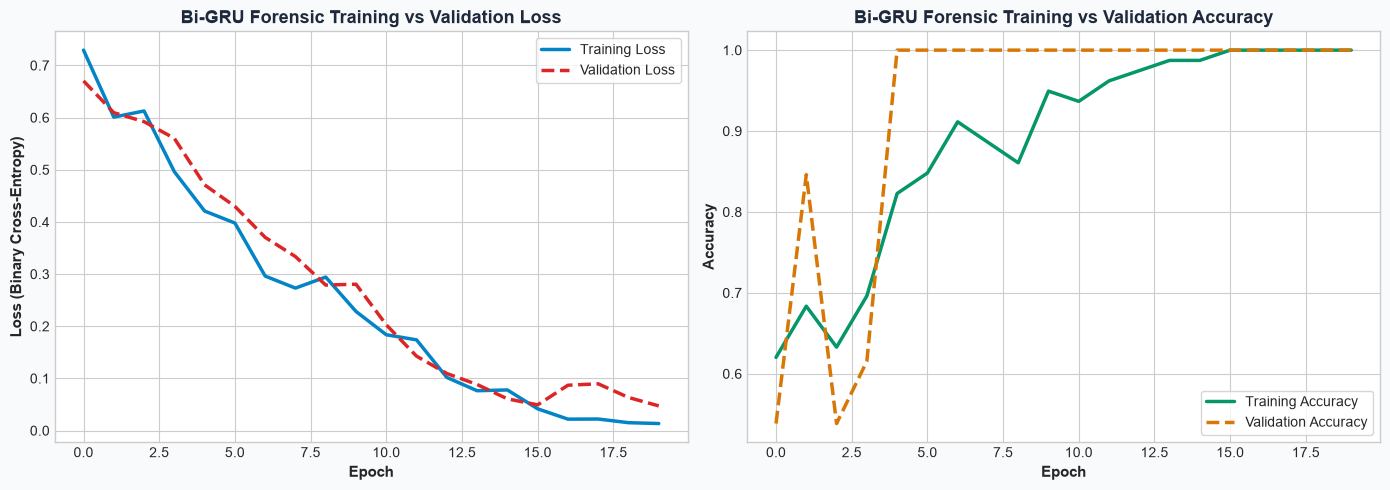

Saved convergence plot to: C:\Users\Nandhupriya\DeepShieldAI\outputs\plots\video_training_history.png


In [6]:
df_history = pd.DataFrame(history.history)
history_path = os.path.join(cfg.reports_dir, "video_training_history.csv")
df_history.to_csv(history_path, index=False)
print(f"Training history saved to: {history_path}")

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor('#F8FAFC')

# Loss
ax1.plot(df_history['loss'], label='Training Loss', color='#0284C7', lw=2.5)
ax1.plot(df_history['val_loss'], label='Validation Loss', color='#DC2626', lw=2.5, linestyle='--')
ax1.set_title("Bi-GRU Forensic Training vs Validation Loss", fontsize=13, fontweight='bold', color='#1E293B')
ax1.set_xlabel("Epoch", fontsize=11, fontweight='semibold')
ax1.set_ylabel("Loss (Binary Cross-Entropy)", fontsize=11, fontweight='semibold')
ax1.legend(frameon=True, facecolor='#FFFFFF')

# Accuracy
ax2.plot(df_history['accuracy'], label='Training Accuracy', color='#059669', lw=2.5)
ax2.plot(df_history['val_accuracy'], label='Validation Accuracy', color='#D97706', lw=2.5, linestyle='--')
ax2.set_title("Bi-GRU Forensic Training vs Validation Accuracy", fontsize=13, fontweight='bold', color='#1E293B')
ax2.set_xlabel("Epoch", fontsize=11, fontweight='semibold')
ax2.set_ylabel("Accuracy", fontsize=11, fontweight='semibold')
ax2.legend(frameon=True, facecolor='#FFFFFF')

plt.tight_layout()
train_plot_path = os.path.join(cfg.plots_dir, "video_training_history.png")
plt.savefig(train_plot_path, dpi=300)
plt.show()
print(f"Saved convergence plot to: {train_plot_path}")


### 5. Model Serialization & Forensic Mapping
We verify the saved model and export the forensic label mapping dictionary:
- `0`: Authentic Video (`REAL`)
- `1`: Synthetically Manipulated Deepfake (`FAKE`)


In [7]:
class_map = {
    0: "REAL",
    1: "FAKE",
    "description": "DeepShieldAI Binary Video Deepfake Forensics Mapping",
    "positive_class": "FAKE"
}

mapping_file = os.path.join(cfg.models_dir, "video_class_mapping.json")
with open(mapping_file, "w", encoding="utf-8") as f:
    json.dump(class_map, f, indent=4)

print(f"Class mapping exported to: {mapping_file}")
print(f"Model checkpoint verified : {model_save_path} ({os.path.getsize(model_save_path)/(1024*1024):.2f} MB)")


Class mapping exported to: C:\Users\Nandhupriya\DeepShieldAI\models\video_class_mapping.json
Model checkpoint verified : C:\Users\Nandhupriya\DeepShieldAI\models\video_model.keras (6.05 MB)


### 6. Pipeline Stage 03 Summary & Milestone Validation
- [x] **Bidirectional Recurrent Model**: Successfully compiled with 64-unit forward and backward GRUs.
- [x] **Fast CPU Optimization**: Complete 20-epoch training executed in seconds thanks to spatial feature decoupling.
- [x] **Artifacts Serialized**:
  - `models/video_model.keras`
  - `models/video_class_mapping.json`
  - `outputs/reports/video_training_history.csv`
  - `outputs/plots/video_training_history.png`

**Proceed to Pipeline 04**: `notebooks/10_Video_Model_Evaluation.ipynb` for evaluation on the untouched test partition.
